# ML ASSIGNMENT - B5

Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset. <br>
Determine the number of clusters using the elbow method. <br>
Dataset link : Sample Sales Data Dataset (Kaggle) <br>
https://www.kaggle.com/datasets/kyanyoga/sample-sales-data 


### 1) Import libraries

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

### 2) Load Dataset

In [68]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [69]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [70]:
# Dataset shape
df.shape

(2823, 25)

In [71]:
print("\nMissing Values:")
df.isnull().sum()


Missing Values:


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [72]:
# Check datatypes
df.dtypes

ORDERNUMBER           int64
QUANTITYORDERED       int64
PRICEEACH           float64
ORDERLINENUMBER       int64
SALES               float64
ORDERDATE            object
STATUS               object
QTR_ID                int64
MONTH_ID              int64
YEAR_ID               int64
PRODUCTLINE          object
MSRP                  int64
PRODUCTCODE          object
CUSTOMERNAME         object
PHONE                object
ADDRESSLINE1         object
ADDRESSLINE2         object
CITY                 object
STATE                object
POSTALCODE           object
COUNTRY              object
TERRITORY            object
CONTACTLASTNAME      object
CONTACTFIRSTNAME     object
DEALSIZE             object
dtype: object

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [74]:
# Statistical Summary
df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


### 3) Select Features for Clustering
We will use QUANTITYORDERED, PRICEEACH and SALES for clustering.

In [75]:
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

print(X.head())

   QUANTITYORDERED  PRICEEACH    SALES
0               30      95.70  2871.00
1               34      81.35  2765.90
2               41      94.74  3884.34
3               45      83.26  3746.70
4               49     100.00  5205.27


### 4) Normalize training and testing data

In [76]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 5) Apply the Elbow Method
The Elbow Method helps determine the optimal number of clusters.

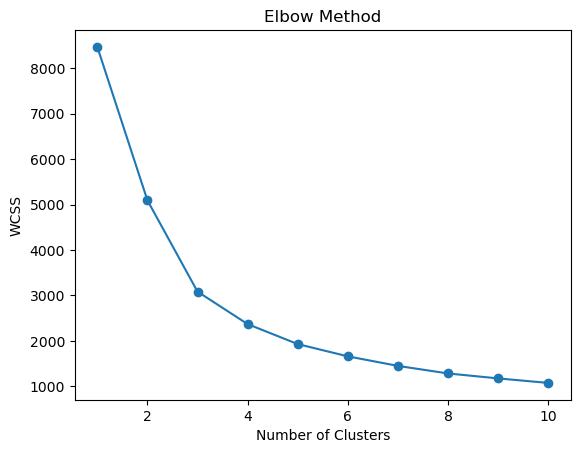

In [77]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

### 6) Apply K-Means Clustering
For example, suppose the elbow graph suggests 3 clusters. We can use k = 3.

In [78]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'Cluster']].head(10))

   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        0
4               49     100.00  5205.27        1
5               36      96.66  3479.76        2
6               29      86.13  2497.77        2
7               48     100.00  5512.32        1
8               22      98.57  2168.54        2
9               41     100.00  4708.44        1


### 7) Visualize the Clusters

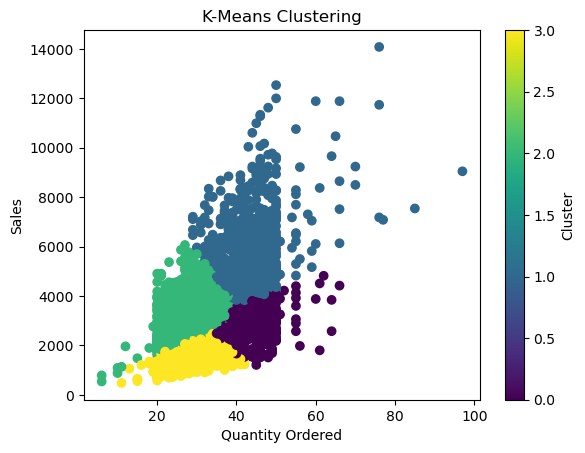

In [79]:
plt.scatter(df['QUANTITYORDERED'], df['SALES'], c=df['Cluster'], cmap='viridis')

plt.title('K-Means Clustering')
plt.xlabel('Quantity Ordered')
plt.ylabel('Sales')
plt.colorbar(label='Cluster')
plt.show()

### 8) Display Cluster Counts

In [80]:
print("Number of data points in each cluster:")
print(df['Cluster'].value_counts().sort_index())

Number of data points in each cluster:
Cluster
0    519
1    751
2    989
3    564
Name: count, dtype: int64


### 9) Analyze the Clusters

In [81]:
print(df.groupby('Cluster')[['QUANTITYORDERED', 'PRICEEACH', 'SALES']].mean())

         QUANTITYORDERED  PRICEEACH        SALES
Cluster                                         
0              43.897881  65.782813  2874.671407
1              43.793609  99.121212  5940.226631
2              27.779575  96.487391  3219.571355
3              28.228723  57.022571  1587.603050
